
# Parte 2 - Modelagem Preditiva

## Objetivo

Desenvolver e avaliar modelos de regressão capazes de prever o `klike_score`, uma pontuação de 0 a 100 que representa a qualidade geral dos criativos publicitários.

A modelagem busca responder:

1. Quais características das campanhas serão utilizadas como variáveis preditoras?
2. Quais modelos apresentam melhor desempenho na previsão do score?
3. Qual a qualidade das previsões considerando MAE, RMSE e R²?
4. Quais características mais contribuem para as previsões?

## Estratégia

Serão utilizados modelos de diferentes níveis de complexidade, priorizando reprodutibilidade, interpretabilidade e aplicabilidade ao produto Klike.

O experimento principal utilizará características do criativo e contexto da campanha, sem depender de métricas de performance observadas após a veiculação.

Posteriormente, poderá ser avaliado um experimento complementar utilizando métricas de performance.


In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import joblib

# Separação dos dados
from sklearn.model_selection import train_test_split

# Pré-processamento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Modelos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# Avaliação
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Interpretação
from sklearn.inspection import permutation_importance

# Validação cruzada
from sklearn.model_selection import KFold, cross_validate

# Clonagem dos estimadores
from sklearn.base import clone

# Exibição de tabelas
from IPython.display import display


In [3]:
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.dpi"] = 125
plt.rcParams["savefig.dpi"] = 180

RANDOM_STATE = 42


In [4]:
# Identificar a raiz do projeto
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "klike_challenge_dataset.csv"
)

FIGURES_PATH = PROJECT_ROOT / "img"

FIGURES_PATH.mkdir(
    parents=True,
    exist_ok=True
)



## Carregamento e inspeção inicial

O dataset utilizado nesta etapa é o mesmo analisado na Parte 1 - Análise Exploratória de Dados.

Antes da modelagem, serão verificadas suas dimensões, a disponibilidade da variável-alvo e as características das variáveis candidatas a preditoras.

O dataset original será preservado, enquanto as transformações necessárias serão realizadas em etapas específicas de pré-processamento.


In [5]:
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"]
)

print("Quantidade de campanhas:", df.shape[0])
print("Quantidade de variáveis:", df.shape[1])

print(
    "Scores ausentes:",
    df["klike_score"].isna().sum()
)

display(df.head())


Quantidade de campanhas: 500
Quantidade de variáveis: 26
Scores ausentes: 0


,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,...,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,...,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,...,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,...,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,...,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,...,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9


## 1 - Feature Engineering

Nesta etapa, serão selecionadas as variáveis utilizadas para prever o `klike_score`.

A seleção considera dois grupos principais:

1. **Características dos criativos:** atributos relacionados ao conteúdo e à estrutura dos vídeos.
2. **Contexto da campanha:** informações sobre a plataforma, público-alvo e objetivo da campanha.

O modelo principal utilizará apenas variáveis disponíveis antes da veiculação, permitindo avaliar sua aplicação na análise e recomendação de melhorias para novos criativos.

As métricas observadas após a publicação, como CTR, ROAS e conversões, serão excluídas deste primeiro experimento.

Essa decisão busca aproximar a modelagem de um cenário real de utilização do produto e evitar a dependência de informações indisponíveis no momento da previsão.


In [6]:
# Definir variável-alvo
TARGET = "klike_score"

# Separar os valores que queremos prever
y = df[TARGET].copy()

# Inspecionar a variável-alvo
print("Quantidade de registros:", y.shape[0])
print("Score mínimo:", y.min())
print("Score máximo:", y.max())
print("Score médio:", round(y.mean(), 2))


Quantidade de registros: 500
Score mínimo: 10.4
Score máximo: 99.1
Score médio: 60.16


In [7]:
# Contexto da campanha
features_contexto = [
    "platform",
    "category",
    "objective",
    "target_audience_age",
    "is_retargeting"
]

# Características dos criativos
features_criativo = [
    "video_duration_s",
    "format",
    "has_subtitle",
    "has_cta",
    "has_hook",
    "has_face",
    "text_density",
    "music_voice_ratio"
]

# Consolidar as features
FEATURES = (
    features_contexto +
    features_criativo
)

# Criar matriz de variáveis preditoras
X = df[FEATURES].copy()

print("Quantidade de features:", X.shape[1])
print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

display(X.head())


Quantidade de features: 13
Dimensão de X: (500, 13)
Dimensão de y: (500,)


,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,has_cta,has_hook,has_face,text_density,music_voice_ratio
0,Meta,Branding,awareness,18-24,False,NaN,vertical,True,True,False,True,medium,0.39
1,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,True,True,True,low,0.07
2,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,True,True,True,medium,0.43
3,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,True,True,True,medium,0.54
4,Meta,Branding,engagement,25-34,False,34.0,vertical,True,True,True,True,low,0.35


### 1.1 - Justificativa da seleção de features

Foram selecionadas 13 variáveis preditoras, divididas entre contexto da campanha e características dos criativos.

**Contexto da campanha**

As variáveis `platform`, `category`, `objective`, `target_audience_age` e `is_retargeting` foram incluídas para representar diferenças entre plataformas, públicos e estratégias de campanha.

**Características dos criativos**

As variáveis de duração, formato, presença de legendas, CTA, hook, rosto humano, densidade de texto e proporção música/voz representam propriedades dos vídeos que podem estar associadas à qualidade dos criativos.

Essas variáveis também possuem relevância para o Recommendations Engine, pois algumas podem orientar modificações concretas nos anúncios.

**Variáveis excluídas**

- `campaign_id`: identificador sem interpretação preditiva direta.
- `date`: inicialmente excluída para manter o modelo simples e evitar incorporar efeitos temporais sem validação específica.
- `impressions`, `clicks`, `ctr`, `cpc`, `spend`, `conversions`, `revenue`, `roas`, `avg_watch_time_s` e `engagement_rate`: métricas observadas após a veiculação.

A exclusão das métricas de performance permite investigar quanto da variação do Klike Score pode ser prevista apenas a partir de informações disponíveis antes da publicação do anúncio.


### 1.2 Criacao de feature — Hook e CTA

A EDA mostrou associacoes entre hook, CTA e CTR. Criamos `hook_cta_interaction` para representar a presenca simultanea desses atributos. A hipotese sera testada comparando os mesmos modelos com e sem essa variavel, usando as mesmas divisões de validacao. Isso nao demonstra causalidade.


In [18]:
# Verificar os tipos de dados das features
tipos_features = pd.DataFrame({
    "Tipo de dado": X.dtypes,
    "Valores ausentes": X.isna().sum(),
    "Valores únicos": X.nunique()
})

display(tipos_features)


,Tipo de dado,Valores ausentes,Valores únicos
platform,object,0,3
category,object,0,5
objective,object,0,5
target_audience_age,object,0,4
is_retargeting,bool,0,2
video_duration_s,float64,39,56
format,object,0,3
has_subtitle,object,46,2
has_cta,bool,0,2
has_hook,bool,0,2


### 1.3 - Estratégia de pré-processamento

As variáveis selecionadas possuem diferentes tipos de dados, exigindo tratamentos específicos antes do treinamento dos modelos.

**Variáveis numéricas**

As variáveis `video_duration_s` e `music_voice_ratio` apresentam valores ausentes. Será utilizada imputação pela mediana, uma estratégia menos sensível a valores extremos.

Também será aplicada padronização para permitir o treinamento de modelos sensíveis à escala, como Ridge Regression.

**Variáveis categóricas e booleanas**

As características categóricas serão representadas utilizando One-Hot Encoding.

Variáveis booleanas serão tratadas como categorias, preservando a interpretação de presença ou ausência de cada característica.

Para `has_subtitle`, os valores ausentes serão representados como uma categoria específica, evitando assumir que a ausência de informação significa `False`.

**Prevenção de data leakage**

Todas as transformações serão implementadas em pipelines ajustados somente sobre os dados de treinamento.


In [19]:
# Variáveis numéricas
features_numericas = [
    "video_duration_s",
    "music_voice_ratio"
]

# Variáveis categóricas
features_categoricas = [
    "platform",
    "category",
    "objective",
    "target_audience_age",
    "format",
    "text_density"
]

# Variáveis booleanas
features_booleanas = [
    "is_retargeting",
    "has_subtitle",
    "has_cta",
    "has_hook",
    "has_face"
]

# Conferir se todas as features estão contempladas
features_organizadas = (
    features_numericas
    + features_categoricas
    + features_booleanas
)

assert set(features_organizadas) == set(FEATURES)

print("Features numéricas:", len(features_numericas))
print("Features categóricas:", len(features_categoricas))
print("Features booleanas:", len(features_booleanas))

features_booleanas_interacao = features_booleanas + ["hook_cta_interaction"]


Features numéricas: 2
Features categóricas: 6
Features booleanas: 5


In [21]:
# Criar cópia da matriz de features
X_modelo = X.copy()

# Converter booleanos para categorias textuais
for coluna in features_booleanas:

    X_modelo[coluna] = X_modelo[coluna].map({
        True: "Sim",
        False: "Não"
    })

# Conferir os valores após a conversão
for coluna in features_booleanas:

    print(f"\n{coluna}")

    print(
        X_modelo[coluna].value_counts(
            dropna=False
        )
    )



is_retargeting
is_retargeting
Não    383
Sim    117
Name: count, dtype: int64

has_subtitle
has_subtitle
Sim    263
Não    191
NaN     46
Name: count, dtype: int64

has_cta
has_cta
Sim    347
Não    153
Name: count, dtype: int64

has_hook
has_hook
Sim    256
Não    244
Name: count, dtype: int64

has_face
has_face
Sim    269
Não    231
Name: count, dtype: int64


In [22]:
# Feature derivada criada apos converter booleanos para "Sim"/"Nao"
X_modelo["hook_cta_interaction"] = (
    (X_modelo["has_hook"] == "Sim") &
    (X_modelo["has_cta"] == "Sim")
).map({True: "Sim", False: "Nao"})

display(X_modelo["hook_cta_interaction"].value_counts())
print("Total de features com interacao:", X_modelo.shape[1])


hook_cta_interaction
Nao    324
Sim    176
Name: count, dtype: int64

Total de features com interacao: 14


### 1.4 - Separação entre treino e teste

O dataset será dividido em dois conjuntos:

- **Treinamento (80%):** utilizado para ajustar os modelos e aprender os parâmetros de pré-processamento.
- **Teste (20%):** reservado para avaliar a capacidade de generalização dos modelos em campanhas não utilizadas no treinamento.

Será utilizada uma divisão aleatória com semente fixa para garantir reprodutibilidade.

Essa abordagem constitui uma avaliação inicial. Como os registros possuem informações temporais, uma validação cronológica poderá ser considerada posteriormente para simular previsões sobre campanhas futuras.


In [23]:
# Mesma divisao para os dois experimentos
X_original = X_modelo.drop(columns=["hook_cta_interaction"])
X_interacao = X_modelo.copy()

indices_treino, indices_teste = train_test_split(
    X_modelo.index, test_size=0.20, random_state=RANDOM_STATE
)

X_train = X_original.loc[indices_treino]
X_test = X_original.loc[indices_teste]
X_train_interacao = X_interacao.loc[indices_treino]
X_test_interacao = X_interacao.loc[indices_teste]
y_train = y.loc[indices_treino]
y_test = y.loc[indices_teste]

print("Treino original:", X_train.shape)
print("Treino com interacao:", X_train_interacao.shape)
print("Teste original:", X_test.shape)
print("Teste com interacao:", X_test_interacao.shape)


Treino original: (400, 13)
Treino com interacao: (400, 14)
Teste original: (100, 13)
Teste com interacao: (100, 14)


### 1.5 - Pipeline de pré-processamento

Nesta etapa, será construído um pipeline de pré-processamento para transformar os dados em um formato adequado aos modelos de regressão.

Serão aplicadas as seguintes transformações:

**Variáveis numéricas**
- Imputação de valores ausentes pela mediana;
- Padronização por meio do StandardScaler.

**Variáveis categóricas e booleanas**
- Representação explícita dos valores ausentes;
- Conversão das categorias para variáveis indicadoras utilizando One-Hot Encoding.

O pré-processamento será integrado ao pipeline de cada modelo, garantindo que as transformações sejam ajustadas somente aos dados de treinamento.

Essa abordagem facilita a reprodutibilidade e reduz o risco de vazamento de informações entre os conjuntos de treino e teste.


In [24]:
pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print("Pipeline numérico configurado.")


Pipeline numérico configurado.


In [25]:
# Consolidar variáveis categóricas e booleanas
features_categoricas_modelo = (
    features_categoricas
    + features_booleanas
)

# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Desconhecido"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

print("Pipeline categórico configurado.")


Pipeline categórico configurado.


In [26]:
# Combinar transformações numéricas e categóricas
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico,
            features_numericas
        ),
        (
            "categoricas",
            pipeline_categorico,
            features_categoricas_modelo
        )
    ],
    remainder="drop"
)

print("Pré-processador configurado.")


Pré-processador configurado.


In [27]:
# Criar uma cópia independente do pré-processador
preprocessador_teste = clone(preprocessador)

# Ajustar somente com dados de treinamento
X_train_transformado = preprocessador_teste.fit_transform(
    X_train
)

# Verificar as dimensões
print("Dimensão original:", X_train.shape)

print(
    "Dimensão após pré-processamento:",
    X_train_transformado.shape
)

# Verificar valores ausentes na matriz transformada
print(
    "Valores ausentes após transformação:",
    np.isnan(
        X_train_transformado.toarray()
        if hasattr(X_train_transformado, "toarray")
        else X_train_transformado
    ).sum()
)


Dimensão original: (400, 13)
Dimensão após pré-processamento: (400, 36)
Valores ausentes após transformação: 0


In [28]:
# Preprocessador adicional para a configuracao com interacao
preprocessador_interacao = ColumnTransformer(
    transformers=[
        ("numericas", clone(pipeline_numerico), features_numericas),
        ("categoricas", clone(pipeline_categorico),
         features_categoricas + features_booleanas_interacao)
    ],
    remainder="drop"
)
print("Preprocessador com interacao configurado.")


Preprocessador com interacao configurado.


In [29]:
# Criar uma cópia independente do pré-processador
preprocessador_teste = clone(preprocessador)

# Ajustar somente com dados de treinamento
X_train_transformado = preprocessador_teste.fit_transform(
    X_train
)

# Verificar as dimensões
print("Dimensão original:", X_train.shape)

print(
    "Dimensão após pré-processamento:",
    X_train_transformado.shape
)

# Verificar valores ausentes na matriz transformada
print(
    "Valores ausentes após transformação:",
    np.isnan(
        X_train_transformado.toarray()
        if hasattr(X_train_transformado, "toarray")
        else X_train_transformado
    ).sum()
)


Dimensão original: (400, 13)
Dimensão após pré-processamento: (400, 36)
Valores ausentes após transformação: 0


### 1.6 - Conclusoes do Feature Engineering

Foram selecionadas 13 variaveis originais de contexto e de caracteristicas dos criativos. Foi criada a feature `hook_cta_interaction`, indicando presenca simultanea de hook e CTA.

Serao comparadas duas configuracoes: **original (13 features)** e **com interacao (14 features)**. A nova feature so sera mantida se a validacao cruzada indicar beneficio preditivo relevante.

As metricas observadas apos a veiculacao foram excluidas do modelo principal. A imputacao, a padronizacao e a codificacao serao ajustadas exclusivamente dentro dos folds de treinamento.


## 2 - Modelo de Regressão


### 2.1 - Escolha e justificativa dos modelos

Para prever o `klike_score`, serão comparadas três abordagens de regressão com diferentes níveis de complexidade.

**Dummy Regressor**

Utilizado como baseline, prevê um valor constante baseado na média dos scores do conjunto de treinamento. Permite verificar se os demais modelos conseguem superar uma estratégia simples.

**Ridge Regression**

Modelo de regressão linear com regularização L2. Foi escolhido por sua simplicidade, interpretabilidade e capacidade de reduzir a magnitude dos coeficientes, especialmente após a codificação de variáveis categóricas.

**Random Forest Regressor**

Modelo baseado em um conjunto de árvores de decisão. Foi escolhido por permitir a representação de relações não lineares e interações entre características dos criativos e o contexto das campanhas.

**Estratégia de comparação**

Os modelos serão comparados utilizando validação cruzada no conjunto de treinamento.

A avaliação final será realizada posteriormente no conjunto de teste, que permanecerá separado durante a escolha dos modelos.


In [17]:
# Definir os modelos de regressão
modelos = {
    "Dummy Regressor": DummyRegressor(
        strategy="mean"
    ),

    "Ridge Regression": Ridge(
        alpha=1.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# Conferir os modelos definidos
for nome, modelo in modelos.items():
    print(f"{nome}: {modelo}")


Dummy Regressor: DummyRegressor()
Ridge Regression: Ridge()
Random Forest: RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)


### 2.2 - Treinamento e validação cruzada dos modelos

Nesta etapa, os modelos serão integrados aos pipelines de pré-processamento e avaliados por meio de validação cruzada.

Será utilizada uma validação cruzada com cinco divisões (5-fold cross-validation), aplicada exclusivamente ao conjunto de treinamento.

Serão comparadas duas configurações de features:

- **Original:** 13 características selecionadas do dataset.
- **Interação:** 14 características, incluindo `hook_cta_interaction`.

Cada configuração será avaliada com Dummy Regressor, Ridge Regression e Random Forest Regressor.

O objetivo é comparar o desempenho dos algoritmos e investigar se a inclusão da nova feature contribui para melhorar as previsões.

O conjunto de teste permanecerá reservado para a avaliação final.


In [31]:
# Configurar a validação cruzada
validacao_cruzada = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Definir as métricas
metricas_validacao = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("Validação cruzada configurada.")


Validação cruzada configurada.


In [32]:
# Dicionário para armazenar os pipelines
pipelines_modelos = {}

for nome, modelo in modelos.items():

    # Experimento com as 13 features originais
    pipelines_modelos[f"{nome} | Original"] = Pipeline(
        steps=[
            (
                "preprocessamento",
                clone(preprocessador)
            ),
            (
                "modelo",
                clone(modelo)
            )
        ]
    )

    # Experimento com a feature de interação
    pipelines_modelos[f"{nome} | Interação"] = Pipeline(
        steps=[
            (
                "preprocessamento",
                clone(preprocessador_interacao)
            ),
            (
                "modelo",
                clone(modelo)
            )
        ]
    )

# Conferir os pipelines
for nome in pipelines_modelos:
    print(nome)


Dummy Regressor | Original
Dummy Regressor | Interação
Ridge Regression | Original
Ridge Regression | Interação
Random Forest | Original
Random Forest | Interação


In [33]:
# Lista para armazenar os resultados
resultados_validacao = []

for nome, pipeline in pipelines_modelos.items():

    print(f"Avaliando: {nome}")

    # Selecionar o conjunto de features
    if nome.endswith("| Interação"):
        X_validacao = X_train_interacao
    else:
        X_validacao = X_train

    # Executar validação cruzada
    scores = cross_validate(
        estimator=pipeline,
        X=X_validacao,
        y=y_train,
        cv=validacao_cruzada,
        scoring=metricas_validacao,
        n_jobs=-1
    )

    # Armazenar os resultados
    resultados_validacao.append({
        "Modelo": nome,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean(),
        "Desvio MAE": scores["test_MAE"].std()
    })

# Criar tabela comparativa
tabela_validacao = pd.DataFrame(
    resultados_validacao
)

# Ordenar pelo menor MAE
tabela_validacao = tabela_validacao.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(tabela_validacao.round(3))


Avaliando: Dummy Regressor | Original
Avaliando: Dummy Regressor | Interação
Avaliando: Ridge Regression | Original
Avaliando: Ridge Regression | Interação
Avaliando: Random Forest | Original
Avaliando: Random Forest | Interação


,Modelo,MAE,RMSE,R2,Desvio MAE
0,Ridge Regression | Original,6.953,8.708,0.675,0.394
1,Ridge Regression | Interação,6.978,8.721,0.674,0.394
2,Random Forest | Interação,7.552,9.583,0.607,0.259
3,Random Forest | Original,7.564,9.586,0.606,0.253
4,Dummy Regressor | Original,12.703,15.679,-0.018,1.111
5,Dummy Regressor | Interação,12.703,15.679,-0.018,1.111


In [34]:
# Copiar os resultados da validação
comparacao_features = tabela_validacao.copy()

# Separar algoritmo e configuração
comparacao_features[
    ["Algoritmo", "Configuração"]
] = comparacao_features["Modelo"].str.split(
    " | ",
    regex=False,
    expand=True
)

# Comparar MAE por algoritmo
comparacao_mae = comparacao_features.pivot(
    index="Algoritmo",
    columns="Configuração",
    values="MAE"
)

# Calcular o ganho obtido com a interação
comparacao_mae["Ganho no MAE"] = (
    comparacao_mae["Original"]
    - comparacao_mae["Interação"]
)

display(comparacao_mae.round(3))


Configuração,Interação,Original,Ganho no MAE
Algoritmo,,,
Dummy Regressor,12.703,12.703,0.000
Random Forest,7.552,7.564,0.013
Ridge Regression,6.978,6.953,-0.025



### 2.3 - Comparação e seleção do modelo

A validação cruzada permitiu comparar três algoritmos de regressão e avaliar a contribuição da feature `hook_cta_interaction`.

**Desempenho dos modelos**

A Ridge Regression com as 13 features originais apresentou o melhor desempenho médio:

- MAE: 6,953 pontos;
- RMSE: 8,708 pontos;
- R²: 0,675.

A Random Forest apresentou desempenho inferior, com MAE de aproximadamente 7,56 pontos, enquanto o Dummy Regressor registrou MAE de 12,70 pontos.

Os resultados indicam que, neste experimento, o modelo linear regularizado apresentou melhor capacidade preditiva do que a abordagem baseada em árvores.

**Avaliação da nova feature**

A inclusão de `hook_cta_interaction` produziu alterações pequenas no desempenho:

- Ridge Regression: aumento do MAE de 6,953 para 6,978.
- Random Forest: redução do MAE de 7,564 para 7,552.
- Dummy Regressor: nenhuma alteração.

A nova feature não apresentou ganho consistente.

**Decisão**

A Ridge Regression com as 13 features originais foi selecionada para a avaliação final.

A escolha considera o menor erro médio na validação cruzada, a simplicidade do modelo e sua interpretabilidade.

O conjunto de teste permaneceu reservado durante a comparação, sendo utilizado somente na próxima etapa.


## 3 - Avaliação do Modelo

Nesta etapa, será avaliado o desempenho final da Ridge Regression com as 13 features originais, selecionada por apresentar o menor MAE médio na validação cruzada.

O modelo será ajustado utilizando as 400 campanhas do conjunto de treinamento e avaliado nas 100 campanhas reservadas para teste.

Serão utilizadas três métricas:

- **MAE:** erro absoluto médio, expresso em pontos do Klike Score.
- **RMSE:** raiz do erro quadrático médio, que penaliza erros maiores.
- **R²:** coeficiente de determinação, que compara o desempenho do modelo com uma previsão constante baseada na média.

Essa avaliação permitirá investigar a capacidade de generalização do modelo para campanhas não utilizadas durante o treinamento.


In [35]:
# Selecionar o melhor pipeline
modelo_final = clone(
    pipelines_modelos["Ridge Regression | Original"]
)

# Treinar com todo o conjunto de treinamento
modelo_final.fit(
    X_train,
    y_train
)

print("Modelo Ridge treinado com sucesso!")


Modelo Ridge treinado com sucesso!


In [36]:
# Gerar previsões para o conjunto de teste
y_pred = modelo_final.predict(X_test)

# Criar tabela comparativa
comparacao_previsoes = pd.DataFrame({
    "Score real": y_test.to_numpy(),
    "Score previsto": y_pred
})

# Calcular erro absoluto
comparacao_previsoes["Erro absoluto"] = (
    comparacao_previsoes["Score real"]
    - comparacao_previsoes["Score previsto"]
).abs()

display(comparacao_previsoes.head(10).round(2))


,Score real,Score previsto,Erro absoluto
0,79.7,76.20,3.50
1,55.5,51.40,4.10
2,55.4,55.49,0.09
3,76.8,78.32,1.52
4,40.6,51.47,10.87
5,56.1,57.67,1.57
6,54.4,54.99,0.59
7,72.4,70.87,1.53
8,68.4,61.48,6.92
9,91.3,85.04,6.26


In [37]:
# Calcular MAE
mae_teste = mean_absolute_error(
    y_test,
    y_pred
)

# Calcular RMSE
rmse_teste = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

# Calcular R²
r2_teste = r2_score(
    y_test,
    y_pred
)

# Organizar resultados
resultados_teste = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Resultado": [
        mae_teste,
        rmse_teste,
        r2_teste
    ]
})

display(resultados_teste.round(3))


,Métrica,Resultado
0,MAE,6.785
1,RMSE,8.749
2,R²,0.661



### 3.1 - Interpretação das métricas de avaliação

A Ridge Regression foi avaliada em 100 campanhas reservadas para teste, não utilizadas durante o treinamento e a seleção do modelo.

**Resultados obtidos:**

- MAE: 6,785 pontos;
- RMSE: 8,749 pontos;
- R²: 0,661.

O MAE indica que as previsões apresentam um erro absoluto médio de aproximadamente 6,8 pontos na escala do Klike Score.

O RMSE superior ao MAE indica maior penalização de erros elevados, sugerindo a necessidade de investigar campanhas com previsões menos precisas.

O R² de 0,661 indica desempenho superior ao de uma previsão constante baseada na média, considerando o erro quadrático no conjunto de teste.

**Comparação com a validação cruzada**

Os resultados no teste ficaram próximos dos valores médios observados na validação cruzada:

- MAE: 6,953 na validação e 6,785 no teste;
- RMSE: 8,708 na validação e 8,749 no teste;
- R²: 0,675 na validação e 0,661 no teste.

Essa proximidade sugere capacidade de generalização para campanhas não utilizadas no treinamento, embora a avaliação esteja limitada ao conjunto de dados disponível.

**Conclusão preliminar**

A Ridge Regression apresentou desempenho consistente com a validação cruzada e superou os modelos alternativos durante a seleção.

Ainda é necessário investigar a distribuição dos erros e identificar possíveis padrões nas previsões.


### 3.2 - Análise das previsões e dos resíduos

Além das métricas agregadas, é importante investigar como os erros se distribuem entre as campanhas.

Serão utilizadas duas visualizações:

1. Comparação entre os scores reais e previstos;
2. Distribuição dos resíduos do modelo.

Essa análise permite identificar possíveis padrões de erro, tendências de superestimação ou subestimação e campanhas com previsões menos precisas.


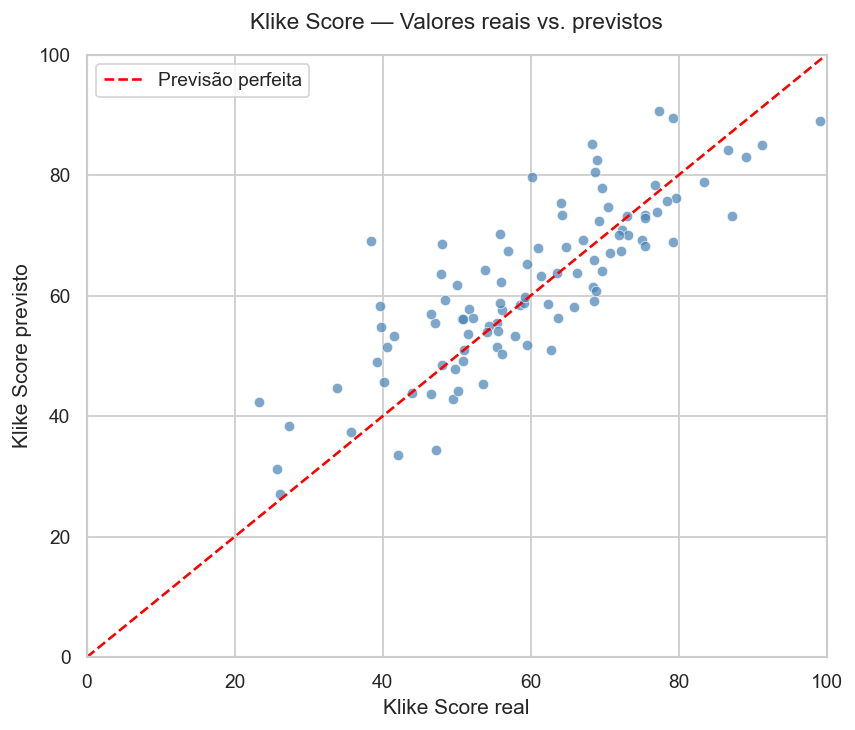

In [38]:
# Criar figura
fig, ax = plt.subplots(figsize=(7, 6))

# Dispersão dos valores reais e previstos
sns.scatterplot(
    x=y_test,
    y=y_pred,
    color="steelblue",
    alpha=0.7,
    ax=ax
)

# Linha de previsão perfeita
ax.plot(
    [0, 100],
    [0, 100],
    color="red",
    linestyle="--",
    label="Previsão perfeita"
)

ax.set_title(
    "Klike Score — Valores reais vs. previstos",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Klike Score real")
ax.set_ylabel("Klike Score previsto")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "score_real_vs_previsto.png",
    bbox_inches="tight"
)

plt.show()


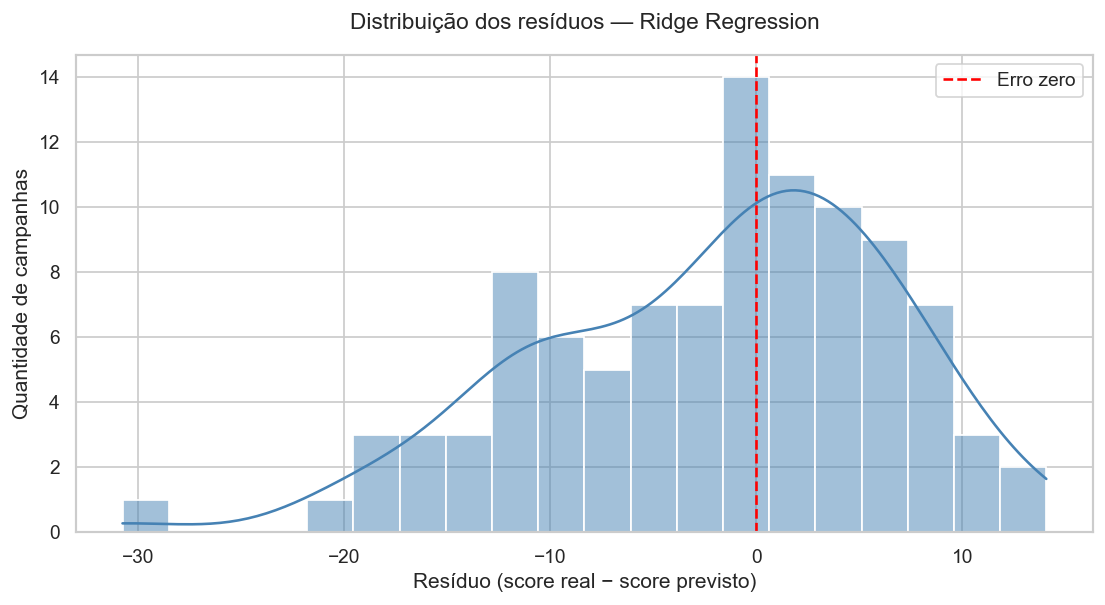

In [39]:
# Calcular resíduos
residuos = (
    y_test.to_numpy() - y_pred
)

# Criar figura
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    residuos,
    bins=20,
    kde=True,
    color="steelblue",
    ax=ax
)

# Linha de referência
ax.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Erro zero"
)

ax.set_title(
    "Distribuição dos resíduos — Ridge Regression",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Resíduo (score real − score previsto)")
ax.set_ylabel("Quantidade de campanhas")

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "distribuicao_residuos.png",
    bbox_inches="tight"
)

plt.show()



### 3.3 - Interpretação dos resultados e limitações

A avaliação da Ridge Regression no conjunto de teste apresentou os seguintes resultados:

- **MAE:** 6,785 pontos;
- **RMSE:** 8,749 pontos;
- **R²:** 0,661.

Os resultados ficaram próximos daqueles observados durante a validação cruzada, sugerindo desempenho relativamente consistente em campanhas não utilizadas no treinamento.

**Análise dos valores reais e previstos**

O gráfico de dispersão revelou uma associação positiva entre os scores reais e as previsões do modelo.

Entretanto, algumas campanhas com scores baixos receberam previsões superiores aos valores observados, enquanto determinados criativos com scores elevados tiveram seus resultados subestimados.

Esse comportamento sugere uma tendência de aproximação das previsões à região central da distribuição.

**Análise dos resíduos**

A distribuição dos resíduos apresentou concentração de observações próximas de zero, mas também erros negativos expressivos, incluindo uma campanha com resíduo próximo de -30 pontos.

Isso indica que, embora o modelo apresente desempenho médio satisfatório, algumas previsões individuais ainda podem apresentar erros relevantes.

**Limitações**

- O dataset contém apenas 500 campanhas simuladas.
- A avaliação final foi realizada em 100 campanhas.
- O modelo utiliza metadados dos criativos, sem acesso ao conteúdo audiovisual original.
- A divisão aleatória não representa necessariamente o desempenho em campanhas futuras.
- A regularização e a estrutura linear podem limitar a representação de relações mais complexas.

**Conclusão**

A Ridge Regression apresentou desempenho consistente com a validação cruzada e foi capaz de prever parte relevante da variação do Klike Score.

Entretanto, os erros observados indicam que as previsões devem ser utilizadas como estimativas de apoio à decisão, e não como avaliações infalíveis da qualidade dos criativos.


## 4 - Feature Importance

Nesta etapa, será investigada a importância das variáveis utilizadas pela Ridge Regression na previsão do `klike_score`.

Será aplicada a técnica de Permutation Importance, que avalia a redução do desempenho preditivo quando os valores de uma variável são embaralhados.

A análise será realizada sobre as 13 features originais, utilizando o pipeline completo de pré-processamento e regressão.

O objetivo é identificar quais características mais contribuem para as previsões e avaliar se os resultados apresentam coerência com os padrões observados na análise exploratória.

A importância preditiva não deve ser interpretada como evidência de causalidade.


In [40]:
# Criar subconjuntos para análise de importância
X_ajuste, X_importancia, y_ajuste, y_importancia = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=RANDOM_STATE
)

# Treinar uma cópia do pipeline selecionado
modelo_importancia = clone(
    pipelines_modelos["Ridge Regression | Original"]
)

modelo_importancia.fit(
    X_ajuste,
    y_ajuste
)

# Calcular Permutation Importance
resultado_importancia = permutation_importance(
    estimator=modelo_importancia,
    X=X_importancia,
    y=y_importancia,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Organizar resultados
tabela_importancia = pd.DataFrame({
    "Feature": X_importancia.columns,
    "Importância média": resultado_importancia.importances_mean,
    "Desvio padrão": resultado_importancia.importances_std
})

# Ordenar por importância
tabela_importancia = tabela_importancia.sort_values(
    by="Importância média",
    ascending=False
)

display(tabela_importancia.round(3))


,Feature,Importância média,Desvio padrão
9,has_hook,5.615,0.902
10,has_face,2.846,0.456
11,text_density,2.391,0.377
7,has_subtitle,1.122,0.301
8,has_cta,1.050,0.265
4,is_retargeting,0.397,0.155
0,platform,0.279,0.174
1,category,0.184,0.089
6,format,0.168,0.095
2,objective,0.077,0.077


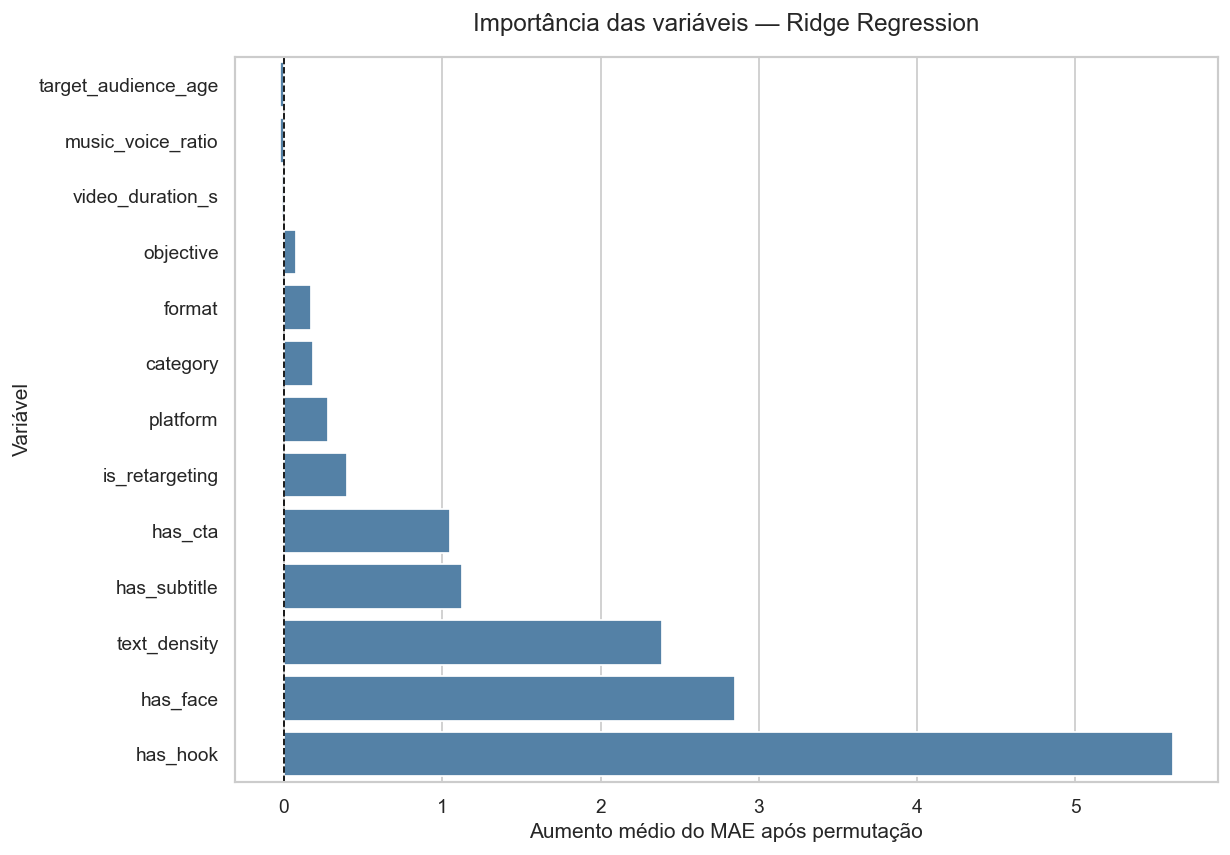

In [41]:
# Ordenar para o gráfico horizontal
dados_grafico = tabela_importancia.sort_values(
    by="Importância média",
    ascending=True
)

# Criar figura
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=dados_grafico,
    x="Importância média",
    y="Feature",
    color="steelblue",
    ax=ax
)

# Linha de referência
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Importância das variáveis — Ridge Regression",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Aumento médio do MAE após permutação")
ax.set_ylabel("Variável")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "feature_importance.png",
    bbox_inches="tight"
)

plt.show()



### 4.1 - Interpretação da importância das variáveis

A análise de Permutation Importance identificou as características que mais contribuem para o desempenho preditivo da Ridge Regression.

**Principais variáveis**

1. `has_hook`: importância média de 5,615 pontos de MAE.
2. `has_face`: importância média de 2,846 pontos.
3. `text_density`: importância média de 2,391 pontos.
4. `has_subtitle`: importância média de 1,122 ponto.
5. `has_cta`: importância média de 1,050 ponto.

Esses resultados indicam que características diretamente relacionadas ao conteúdo e à estrutura dos criativos apresentam maior contribuição preditiva do que diversas variáveis de contexto.

**Coerência com a análise exploratória**

Na EDA, a presença de hook e de rosto humano apresentou associação positiva com o CTR.

Também foram observadas diferenças de performance relacionadas à densidade de texto.

A importância dessas características na modelagem é coerente com os padrões identificados anteriormente, embora as métricas analisadas sejam diferentes.

**Variáveis com baixa importância**

Duração do vídeo, proporção música/voz e faixa etária apresentaram importâncias próximas de zero ou ligeiramente negativas.

Isso indica que, na amostra de validação utilizada, o embaralhamento dessas variáveis não prejudicou significativamente o desempenho do modelo.

**Limitações**

A Permutation Importance mede contribuição preditiva, não causalidade.

Além disso, variáveis correlacionadas podem compartilhar informação, afetando suas importâncias individuais.

Os resultados também dependem da amostra utilizada para avaliação.

**Conclusão**

As características `has_hook`, `has_face` e `text_density` foram as mais relevantes para a previsão do Klike Score.

Esses resultados sugerem que atributos relacionados à captura de atenção, presença humana e organização visual do criativo merecem atenção especial em análises futuras.

Entretanto, a importância preditiva não deve ser utilizada isoladamente para recomendar modificações ou estimar ganhos de performance.


### 4.2 - Coeficientes da Ridge Regression

Além da importância por permutação, serão analisados os coeficientes da Ridge Regression para investigar a direção das associações entre as características dos criativos e o Klike Score previsto.

Como o modelo utiliza One-Hot Encoding para variáveis categóricas, cada categoria é representada por uma coluna específica.

Os coeficientes positivos indicam contribuições positivas para a previsão, enquanto os negativos indicam contribuições negativas, mantendo constantes as demais variáveis representadas no modelo.

Para variáveis categóricas codificadas por One-Hot Encoding completo, os coeficientes individuais não devem ser interpretados isoladamente como efeitos em relação a uma categoria de referência.

A interpretação será realizada considerando o conjunto de categorias de cada variável e as limitações de um modelo observacional.


In [42]:
# Recuperar o pré-processador treinado
preprocessador_treinado = modelo_final.named_steps[
    "preprocessamento"
]

# Recuperar o modelo Ridge treinado
ridge_treinada = modelo_final.named_steps[
    "modelo"
]

# Recuperar os nomes das features transformadas
nomes_features = (
    preprocessador_treinado.get_feature_names_out()
)

# Recuperar os coeficientes
coeficientes = ridge_treinada.coef_

# Organizar os resultados
tabela_coeficientes = pd.DataFrame({
    "Feature": nomes_features,
    "Coeficiente": coeficientes
})

# Calcular magnitude dos coeficientes
tabela_coeficientes["Magnitude"] = (
    tabela_coeficientes["Coeficiente"].abs()
)

# Ordenar por magnitude
tabela_coeficientes = tabela_coeficientes.sort_values(
    by="Magnitude",
    ascending=False
)

display(tabela_coeficientes.round(3))


,Feature,Coeficiente,Magnitude
33,categoricas__has_hook_Sim,9.012,9.012
32,categoricas__has_hook_Não,-9.012,9.012
22,categoricas__text_density_high,-7.135,7.135
24,categoricas__text_density_medium,6.875,6.875
35,categoricas__has_face_Sim,6.031,6.031
34,categoricas__has_face_Não,-6.031,6.031
29,categoricas__has_subtitle_Sim,4.413,4.413
30,categoricas__has_cta_Não,-3.706,3.706
31,categoricas__has_cta_Sim,3.706,3.706
28,categoricas__has_subtitle_Não,-3.631,3.631


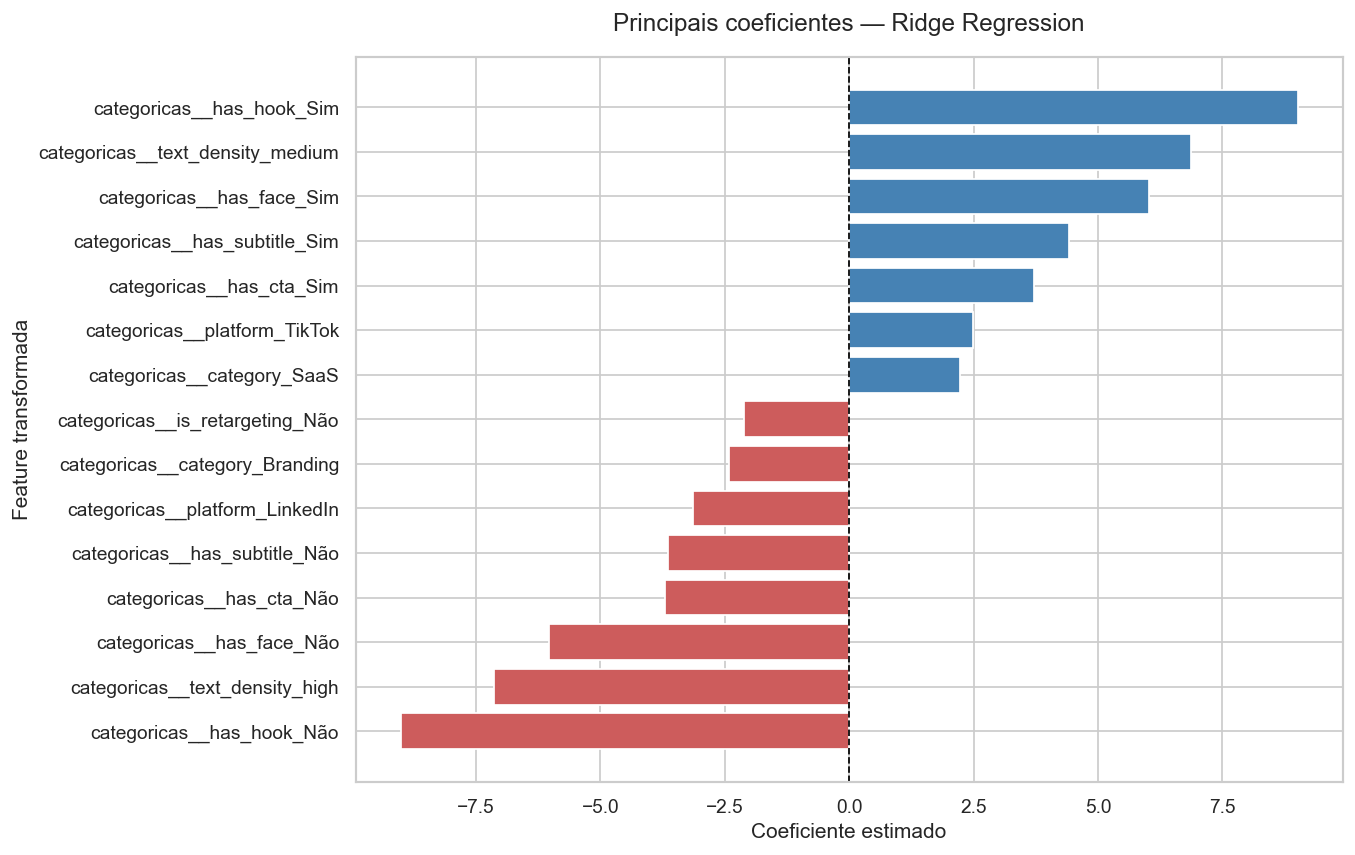

In [43]:
# Selecionar os 15 coeficientes de maior magnitude
top_coeficientes = tabela_coeficientes.head(15).copy()

# Ordenar para visualização
top_coeficientes = top_coeficientes.sort_values(
    by="Coeficiente",
    ascending=True
)

# Definir cores conforme o sinal
cores = [
    "steelblue" if valor >= 0 else "indianred"
    for valor in top_coeficientes["Coeficiente"]
]

# Criar figura
fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_coeficientes["Feature"],
    top_coeficientes["Coeficiente"],
    color=cores
)

# Linha de referência
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Principais coeficientes — Ridge Regression",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Coeficiente estimado")
ax.set_ylabel("Feature transformada")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "coeficientes_ridge.png",
    bbox_inches="tight"
)

plt.show()


In [44]:
# Criar duas versões das mesmas campanhas
X_sem_hook = X_test.copy()
X_com_hook = X_test.copy()

# Modificar somente a presença de hook
X_sem_hook["has_hook"] = "Não"
X_com_hook["has_hook"] = "Sim"

# Gerar previsões
previsoes_sem_hook = modelo_final.predict(
    X_sem_hook
)

previsoes_com_hook = modelo_final.predict(
    X_com_hook
)

# Calcular diferença nas previsões
diferenca_hook = (
    previsoes_com_hook - previsoes_sem_hook
)

print(
    "Diferença média prevista ao alternar hook:",
    round(diferenca_hook.mean(), 3),
    "pontos"
)


Diferença média prevista ao alternar hook: 18.024 pontos



### 4.2.1 - Interpretação dos coeficientes

A análise dos coeficientes da Ridge Regression permitiu investigar a direção das associações entre características dos criativos e o Klike Score previsto.

**Presença de hook**

A diferença entre os coeficientes das categorias "Sim" e "Não" foi de aproximadamente 18,024 pontos.

Isso significa que, mantendo as demais variáveis constantes, o modelo atribui uma previsão 18,024 pontos maior a campanhas com hook.

**Presença de rosto humano**

A diferença prevista entre campanhas com e sem rosto humano foi de aproximadamente 12,062 pontos, indicando uma associação positiva no modelo.

**Legendas e CTA**

A presença de legendas apresentou contraste previsto de aproximadamente 8,119 pontos, enquanto a presença de CTA apresentou contraste de aproximadamente 7,412 pontos.

**Densidade de texto**

A densidade média apresentou o maior coeficiente positivo (+6,875), enquanto a densidade alta apresentou coeficiente negativo (-7,135).

A mudança de densidade alta para média corresponde a uma diferença prevista de aproximadamente 14,010 pontos, mantendo constantes as demais características.

**Interpretação de negócio**

Os resultados sugerem que características relacionadas à captura de atenção, presença humana e organização visual possuem associações relevantes com o Klike Score previsto.

Esses padrões apresentam coerência parcial com a análise exploratória, embora as métricas de performance e o Klike Score não representem exatamente a mesma dimensão de qualidade.

**Limitações**

Os coeficientes representam associações aprendidas pelo modelo, não efeitos causais.

As diferenças previstas não devem ser interpretadas como ganhos garantidos decorrentes de alterações nos criativos.

Além disso, os contrastes foram calculados em um modelo linear aditivo, que não representa explicitamente interações entre características.


### 4.3 - Persistência do modelo

Para permitir a utilização do modelo preditivo no Recommendations Engine, o pipeline final da Ridge Regression será serializado utilizando a biblioteca Joblib.

O arquivo armazenará o modelo treinado e as etapas de pré-processamento, incluindo imputação, padronização e codificação das variáveis categóricas.

Essa abordagem permite reutilizar o modelo em outros módulos do projeto sem repetir o treinamento.

O arquivo deverá ser carregado apenas em ambientes confiáveis, pois a desserialização de objetos Python pode executar código.


In [47]:
# Criar diretório para armazenar o modelo
MODELS_PATH = PROJECT_ROOT / "models"

MODELS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# Definir caminho do modelo
MODEL_PATH = MODELS_PATH / "ridge_klike_score.joblib"

# Salvar o pipeline treinado
joblib.dump(
    modelo_final,
    MODEL_PATH
)

print("Modelo salvo em:", MODEL_PATH)


Modelo salvo em: c:\Users\user\OneDrive\Desktop\klikeIA_case\models\ridge_klike_score.joblib
